IQAE + Noise + Search algorithm (See Appendix Implementation)
This is desgined such that the threshold frontier can be more accurately and more efficiently identified

This jupyter notebook is for the variaton of N_shots


In [1]:
# ══════════════════════════════════════════════════════════════════════════════
# Prerequisites: Qiskit 0.45.0, Qiskit Aer 0.20.0, Qiskit Algorithms 0.6.0
# ══════════════════════════════════════════════════════════════════════════════

# ── Imports ───────────────────────────────────────────────────────────────────
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from qiskit.circuit import QuantumCircuit
from qiskit import transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit_aer.primitives import Sampler as AerSampler
from qiskit_algorithms import IterativeAmplitudeEstimation, EstimationProblem

print("All imports OK ✅")

# ── Noise Model Builder ────────────────────────────────────────────────────────
SINGLE_QUBIT_GATES = [
    'id', 'x', 'y', 'z', 'h', 's', 'sdg', 't', 'tdg',
    'sx', 'sxdg', 'rx', 'ry', 'rz', 'u', 'u1', 'u2', 'u3', 'p'
]

def build_noisy_sampler(p_depol, n_shots):
    if p_depol > 0.0:
        noise_model = NoiseModel()
        noise_model.add_all_qubit_quantum_error(
            depolarizing_error(min(p_depol, 1.0), 1), SINGLE_QUBIT_GATES
        )
        return AerSampler(
            backend_options={"noise_model": noise_model},
            run_options={"shots": n_shots}
        )
    return AerSampler(run_options={"shots": n_shots})

# ── Bernoulli Circuits ─────────────────────────────────────────────────────────
p_true = 0.2

class BernoulliA(QuantumCircuit):
    def __init__(self, probability):
        super().__init__(1)
        self.ry(2 * np.arcsin(np.sqrt(probability)), 0)

class BernoulliQ(QuantumCircuit):
    def __init__(self, probability):
        super().__init__(1)
        self._theta_p = 2 * np.arcsin(np.sqrt(probability))
        self.ry(2 * self._theta_p, 0)

    def power(self, k):
        q_k = QuantumCircuit(1)
        q_k.ry(2 * k * self._theta_p, 0)
        return q_k

# ── Estimation Problem ─────────────────────────────────────────────────────────
problem = EstimationProblem(
    state_preparation=BernoulliA(p_true),
    grover_operator=BernoulliQ(p_true),
    objective_qubits=[0],
)
print("Problem defined ✅")

All imports OK ✅
Problem defined ✅


In [ ]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL 1 — Parameters + Helper Functions  (fixed)
# ══════════════════════════════════════════════════════════════════════════════

import numpy as np
from joblib import Parallel, delayed

p_true    = 0.2
N_SHOTS   = 200
R         = 500
ALPHA     = 0.05
N_JOBS    = 18

TARGET         = 0.50
CONV_BAND = 0.02
LOCAL_HALF_WIDTH = 0.02   # accept s ∈ [0.4875, 0.5125]  ← matches agreed pseudocode
CLIFF_THRESH   = 0.05    # deviation > 0.05 from TARGET triggers cliff/drop logic
PRECISION      = 0.0001

epsilon_values = [e for e in np.linspace(0.0001, 0.1, 1000).tolist() if e <= 0.75]

# ── Wilson Score ──────────────────────────────────────────────────────────────
Z_95 = 1.96

def wilson_score(k, n, z=Z_95):
    p_hat      = k / n
    z2n        = z**2 / n
    centre     = (p_hat + z2n / 2) / (1 + z2n)
    half_width = (z * np.sqrt(p_hat * (1-p_hat) / n + z2n / 4)) / (1 + z2n)
    lower      = np.clip(centre - half_width, 0.0, 1.0)
    upper      = np.clip(centre + half_width, 0.0, 1.0)
    return float(p_hat), float(lower), float(upper), float(half_width)

In [3]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL 2 — Single run + Probe
# ══════════════════════════════════════════════════════════════════════════════

def single_run(p_noise, eps):
    """One IQAE run. Returns 1 (success) or 0 (failure)."""
    try:
        sampler = build_noisy_sampler(p_noise, N_SHOTS)
        iae     = IterativeAmplitudeEstimation(
            epsilon_target = eps,
            alpha          = ALPHA,
            sampler        = sampler,
        )
        result  = iae.estimate(problem)
        # ✅ Use estimation_processed — the final probability in [0,1]
        return 1 if abs(result.estimation_processed - p_true) <= eps else 0
    except Exception as e:
        print(f"[WARN] single_run failed: {type(e).__name__}: {e}")
        return 0


def probe(eps, p):
    """
    Run R independent IQAE runs at (eps, p) in parallel.
    Returns (s_hat, lower_CI, upper_CI, half_width).
    """
    outcomes           = Parallel(n_jobs=N_JOBS)(
        delayed(single_run)(p, eps) for _ in range(R)
    )
    k                  = sum(outcomes)
    s_hat, lo, hi, hw  = wilson_score(k, R)
    return s_hat, lo, hi, hw

In [4]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL 3 — Bisection
# ══════════════════════════════════════════════════════════════════════════════

def find_boundary(eps, p_low, p_high):
    """
    Bisect over p to find p* where success rate ≈ 50% ± CONV_BAND.
    Matches the pseudocode agreed in transcript exactly.
    """
    history = []

    while (p_high - p_low) > PRECISION:

        p_mid             = (p_low + p_high) / 2.0
        s_hat, lo, hi, hw = probe(eps, p_mid)

        history.append({
            "p_try"       : p_mid,
            "s_hat"       : s_hat,
            "wilson_lower": lo,
            "wilson_upper": hi,
            "wilson_hw"   : hw,
        })

        print(f"    ε={eps:.4f} | p={p_mid:.4f} | "
              f"s={s_hat:.3f} [{lo:.3f}, {hi:.3f}] | "
              f"window=[{p_low:.4f}, {p_high:.4f}]")

        if s_hat > TARGET + CONV_BAND:
            p_low  = p_mid

        elif s_hat < TARGET - CONV_BAND:
            p_high = p_mid

        else:
            print(f"    ✅ Converged at p={p_mid:.4f}")
            return {
                "epsilon"     : eps,
                "p_star"      : p_mid,
                "s_hat"       : s_hat,
                "wilson_lower": lo,
                "wilson_upper": hi,
                "wilson_hw"   : hw,
                "converged"   : True,
                "cliff"       : False,
                "history"     : history,
                "final_p_low" : p_low,
                "final_p_high": p_high,
            }

    p_best            = (p_low + p_high) / 2.0
    s_hat, lo, hi, hw = probe(eps, p_best)

    print(f"    ⚠️  Precision limit at p={p_best:.4f} | s={s_hat:.3f}")
    return {
        "epsilon"     : eps,
        "p_star"      : p_best,
        "s_hat"       : s_hat,
        "wilson_lower": lo,
        "wilson_upper": hi,
        "wilson_hw"   : hw,
        "converged"   : False,
        "cliff"       : False,
        "history"     : history,
        "final_p_low" : p_low,
        "final_p_high": p_high,
    }

In [5]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL 4 — Outer sweep (added: early termination if p* saturates at 1.0)
# ══════════════════════════════════════════════════════════════════════════════

P_STAR_SATURATION = 0.999

def sweep_frontier(epsilon_list, local_half_width=LOCAL_HALF_WIDTH):

    results     = []
    p_star_prev = None

    for eps in epsilon_list:

        print(f"\n{'─'*60}")
        print(f"  ε = {eps:.4f}")
        print(f"{'─'*60}")

        # ── CASE 1: First epsilon ─────────────────────────────────────────────
        if p_star_prev is None:
            p_low  = 0.0
            p_high = 1.0
            cliff  = False
            print("  First ε — bisecting full range [0.0, 1.0]")

        # ── CASE 2: Subsequent epsilons ───────────────────────────────────────
        else:

            # ── Early termination ─────────────────────────────────────────────
            if p_star_prev >= P_STAR_SATURATION:
                print(f"  🛑 Early termination: p* = {p_star_prev:.4f} has "
                      f"reached the physical noise ceiling. "
                      f"All remaining ε trivially succeed. Stopping.")
                break

            print(f"  Probing at previous p* = {p_star_prev:.4f} ...")
            s_probe, lo, hi, hw = probe(eps, p_star_prev)
            print(f"  Probe: s={s_probe:.3f} [{lo:.3f}, {hi:.3f}]")

            if abs(s_probe - TARGET) <= CONV_BAND:
                p_low  = max(0.0, p_star_prev - local_half_width)
                p_high = min(1.0, p_star_prev + local_half_width)
                cliff  = False
                print(f"  Near boundary — local refinement in "
                      f"[{p_low:.4f}, {p_high:.4f}]")

            elif s_probe > TARGET + CONV_BAND:
                p_low  = p_star_prev
                p_high = 1.0
                cliff  = True
                print(f"  ⚠️  Cliff detected (s={s_probe:.3f}) — "
                      f"searching [{p_low:.4f}, {p_high:.4f}]")

            else:
                p_low  = 0.0
                p_high = p_star_prev
                cliff  = False
                print(f"  ⚠️  Boundary dropped (s={s_probe:.3f}) — "
                      f"searching [{p_low:.4f}, {p_high:.4f}]")

        # ── Bisect ────────────────────────────────────────────────────────────
        result          = find_boundary(eps, p_low, p_high)
        result["cliff"] = cliff
        result["search_window_low"]  = p_low
        result["search_window_high"] = p_high
        result["used_local_refinement"] = (
            p_star_prev is not None
            and abs(result["search_window_low"]
                    - max(0.0, p_star_prev - local_half_width)) < 1e-12
            and abs(result["search_window_high"]
                    - min(1.0, p_star_prev + local_half_width)) < 1e-12
            if p_star_prev is not None else False
        )

        results.append(result)
        p_star_prev = result["p_star"]

        status = "✅ converged" if result["converged"] else "⚠️  precision limit"
        print(f"\n  {status} | p* = {result['p_star']:.4f} | "
              f"s = {result['s_hat']:.3f}")

        # ── Post-step saturation check ─────────────────────────────────────
        # Checked after append so the saturated point is still saved
        if result["p_star"] >= P_STAR_SATURATION:
            print(f"\n  🛑 p* = {result['p_star']:.4f} reached the physical "
                  f"noise ceiling. Terminating after this point.")
            break

    return results

In [6]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL 5 — Full run
# ══════════════════════════════════════════════════════════════════════════════

frontier_results = sweep_frontier(epsilon_values)

print(f"\n{'═'*60}")
print(f"  ✅ Frontier sweep complete — {len(frontier_results)} points")
print(f"{'═'*60}")

for r in frontier_results:
    cliff_tag = " ⚠️  CLIFF" if r["cliff"] else ""
    conv_tag  = "✅" if r["converged"] else "⚠️ "
    print(f"  {conv_tag} ε={r['epsilon']:.4f} | "
          f"p*={r['p_star']:.4f} | "
          f"s={r['s_hat']:.3f}{cliff_tag}")


────────────────────────────────────────────────────────────
  ε = 0.0001
────────────────────────────────────────────────────────────
  First ε — bisecting full range [0.0, 1.0]
    ε=0.0001 | p=0.5000 | s=0.000 [0.000, 0.089] | window=[0.0000, 1.0000]
    ε=0.0001 | p=0.2500 | s=0.068 [0.000, 0.159] | window=[0.0000, 0.5000]
    ε=0.0001 | p=0.1250 | s=0.634 [0.538, 0.728] | window=[0.0000, 0.2500]
    ε=0.0001 | p=0.1875 | s=0.280 [0.188, 0.375] | window=[0.1250, 0.2500]
    ε=0.0001 | p=0.1562 | s=0.464 [0.369, 0.560] | window=[0.1250, 0.1875]
    ε=0.0001 | p=0.1406 | s=0.532 [0.436, 0.627] | window=[0.1250, 0.1562]
    ε=0.0001 | p=0.1484 | s=0.502 [0.406, 0.598] | window=[0.1406, 0.1562]
    ✅ Converged at p=0.1484

  ✅ converged | p* = 0.1484 | s = 0.502

────────────────────────────────────────────────────────────
  ε = 0.0006
────────────────────────────────────────────────────────────
  Probing at previous p* = 0.1484 ...
  Probe: s=0.532 [0.436, 0.627]
  ⚠️  Cliff detected

KeyboardInterrupt: 

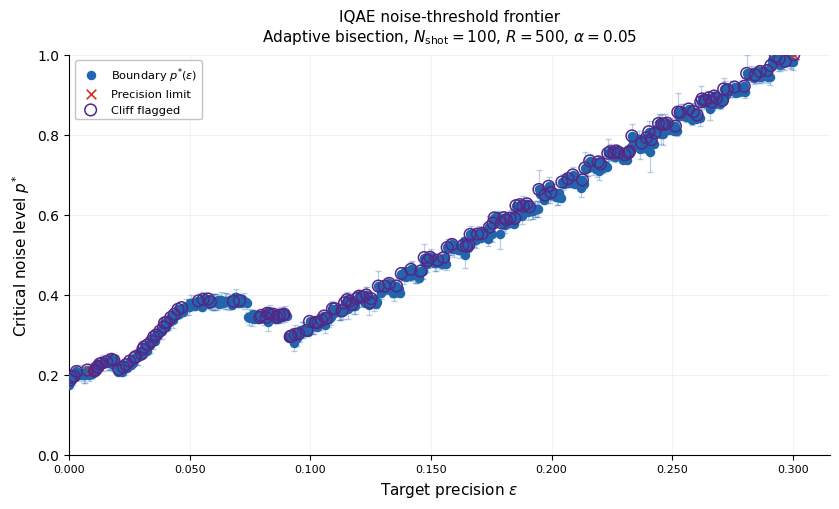

In [14]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL 6 — Plot (error bars from final bisection bracket)
# ══════════════════════════════════════════════════════════════════════════════

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np


def estimate_p_star_uncertainty(result, precision=PRECISION):
    """
    Return asymmetric uncertainty on p* in p-units.

    Preferred source:
      - final bisection bracket [final_p_low, final_p_high]

    Fallback:
      - symmetric ± precision/2 if the bracket was not stored
    """
    p_star = float(result["p_star"])

    if "final_p_low" in result and "final_p_high" in result:
        p_low = float(result["final_p_low"])
        p_high = float(result["final_p_high"])

        lower_err = max(0.0, p_star - p_low)
        upper_err = max(0.0, p_high - p_star)
    else:
        err = precision / 2.0
        lower_err = err
        upper_err = err

    lower_err = min(lower_err, p_star)
    upper_err = min(upper_err, 1.0 - p_star)

    return float(lower_err), float(upper_err)


# ── Build plotting arrays ─────────────────────────────────────────────────────
eps_vals    = [r["epsilon"] for r in frontier_results]
p_star_vals = [r["p_star"] for r in frontier_results]
conv_mask   = [r["converged"] for r in frontier_results]
cliff_mask  = [r.get("cliff", False) for r in frontier_results]

lower_errs, upper_errs = [], []
for r in frontier_results:
    lo, hi = estimate_p_star_uncertainty(r)
    lower_errs.append(lo)
    upper_errs.append(hi)

yerr = np.array([lower_errs, upper_errs])  # shape (2, N) for asymmetric bars

# ── Figure setup ──────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8.5, 5.2))

ax.errorbar(
    eps_vals,
    p_star_vals,
    yerr=yerr,
    fmt='none',
    ecolor='#2166ac',
    alpha=0.30,
    capsize=2.5,
    elinewidth=0.9,
    label='_nolegend_'
)

conv_eps = [e for e, cv in zip(eps_vals, conv_mask) if cv]
conv_p   = [p for p, cv in zip(p_star_vals, conv_mask) if cv]
ax.scatter(
    conv_eps, conv_p,
    color='#2166ac', s=34, zorder=3,
    label=r'Boundary $p^{*}(\varepsilon)$'
)

nc_eps = [e for e, cv in zip(eps_vals, conv_mask) if not cv]
nc_p   = [p for p, cv in zip(p_star_vals, conv_mask) if not cv]
if nc_eps:
    ax.scatter(
        nc_eps, nc_p,
        color='#d73027', marker='x', s=48, linewidths=1.2, zorder=4,
        label='Precision limit'
    )

cliff_eps = [e for e, cf in zip(eps_vals, cliff_mask) if cf]
cliff_p   = [p for p, cf in zip(p_star_vals, cliff_mask) if cf]
if cliff_eps:
    ax.scatter(
        cliff_eps, cliff_p,
        facecolors='none', edgecolors='#542788', s=70, linewidths=1.1, zorder=5,
        label='Cliff flagged'
    )

ax.set_xscale('linear')
ax.xaxis.set_major_formatter(ticker.FormatStrFormatter('%.3f'))
ax.tick_params(axis='x', labelsize=8)

ax.set_xlabel(r'Target precision $\varepsilon$', fontsize=11)
ax.set_ylabel(r'Critical noise level $p^{*}$', fontsize=11)
ax.set_title(
    r'IQAE noise-threshold frontier' + '\n' +
    rf'Adaptive bisection, $N_{{\mathrm{{shot}}}}={N_SHOTS}$, $R={R}$, $\alpha={ALPHA}$',
    fontsize=11,
    pad=10
)

ax.legend(fontsize=8.2, framealpha=0.92, edgecolor='0.75', loc='upper left', ncol=1)
ax.grid(True, which='both', alpha=0.22, linewidth=0.5)
ax.set_xlim(left=0.0, right=max(eps_vals) * 1.05)
ax.set_ylim(0.0, 1)

for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

In [15]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL 7 — Export compact frontier data points + run parameters to a TXT file
# ══════════════════════════════════════════════════════════════════════════════

from datetime import datetime
import os
import math


def _safe_get(name, default="<UNSET>"):
    return globals().get(name, default)


def _format_scalar(x):
    try:
        import numpy as np
        if isinstance(x, (np.floating, np.integer)):
            return x.item()
    except Exception:
        pass
    return x


def _format_epsilon_values_as_linspace(vals):
    """Return a compact np.linspace(...) string if the grid is evenly spaced."""
    try:
        vals = list(vals)
        if len(vals) >= 2:
            start = float(vals[0])
            stop = float(vals[-1])
            num = len(vals)
            step = (stop - start) / (num - 1)

            evenly_spaced = all(
                math.isclose(float(vals[i + 1]) - float(vals[i]), step, rel_tol=1e-9, abs_tol=1e-12)
                for i in range(num - 1)
            )

            if evenly_spaced:
                return f"np.linspace({start:.6f}, {stop:.6f}, {num}).tolist()"
    except Exception:
        pass

    return repr(vals)


def _p_star_error_bounds(r, precision):
    """
    Return (lower_err, upper_err) on p_star for a single frontier result dict.

    Preferred source: final bisection bracket [final_p_low, final_p_high].
    Fallback: symmetric ± precision/2 if the bracket was not stored.
    Mirrors estimate_p_star_uncertainty from Cell 6 so the exported file and
    the plot always agree.
    """
    p_star = float(r.get("p_star", float("nan")))

    if "final_p_low" in r and "final_p_high" in r:
        p_low = float(r["final_p_low"])
        p_high = float(r["final_p_high"])
        lower_err = max(0.0, p_star - p_low)
        upper_err = max(0.0, p_high - p_star)
    else:
        err = precision / 2.0
        lower_err = err
        upper_err = err

    lower_err = min(lower_err, p_star)
    upper_err = min(upper_err, 1.0 - p_star)
    return float(lower_err), float(upper_err)


def export_frontier_points_txt(
    frontier_results,
    filename="iqae_frontier_points_export.txt",
    extra_notes=None,
):
    """
    Export the frontier data points plus run parameters to a TXT file.

    The file contains:
      1. timestamp
      2. top-level experiment parameters
      3. frontier data points, including asymmetric p_star uncertainty
         derived from the final bisection bracket
    """

    epsilon_values = _safe_get("epsilon_values")
    precision = _safe_get("PRECISION", 0.0001)

    params = {
        "timestamp": datetime.now().isoformat(timespec="seconds"),
        "p_true": _format_scalar(_safe_get("p_true")),
        "N_SHOTS": _format_scalar(_safe_get("N_SHOTS")),
        "R": _format_scalar(_safe_get("R")),
        "ALPHA": _format_scalar(_safe_get("ALPHA")),
        "N_JOBS": _format_scalar(_safe_get("N_JOBS")),
        "TARGET": _format_scalar(_safe_get("TARGET")),
        "CONV_BAND": _format_scalar(_safe_get("CONV_BAND")),
        "CLIFF_THRESH": _format_scalar(_safe_get("CLIFF_THRESH")),
        "PRECISION": _format_scalar(_safe_get("PRECISION")),
        "epsilon_values": _format_epsilon_values_as_linspace(epsilon_values)
            if epsilon_values != "<UNSET>" else "<UNSET>",
        "SINGLE_QUBIT_GATES": _format_scalar(_safe_get("SINGLE_QUBIT_GATES")),
    }

    optional_names = [
        "r_min",
        "Z_95",
        "backend_name",
        "noise_model_name",
        "sampler_type",
    ]
    for name in optional_names:
        if name in globals():
            params[name] = _format_scalar(globals()[name])

    lines = []
    lines.append("=" * 80)
    lines.append("IQAE FRONTIER DATA POINTS EXPORT")
    lines.append("=" * 80)
    lines.append("")

    lines.append("[RUN PARAMETERS]")
    for k, v in params.items():
        lines.append(f"{k}: {v}")
    if extra_notes is not None:
        lines.append(f"extra_notes: {extra_notes}")
    lines.append("")

    lines.append("[FRONTIER DATA POINTS]")
    header = ("epsilon | p_star | p_star_lower_err | p_star_upper_err | "
               "s_hat | converged | cliff")
    lines.append(header)
    lines.append("-" * len(header))

    for r in frontier_results:
        eps = float(r.get("epsilon", float("nan")))
        p_star = float(r.get("p_star", float("nan")))
        s_hat = float(r.get("s_hat", float("nan")))
        converged = r.get("converged", False)
        cliff = r.get("cliff", False)

        lower_err, upper_err = _p_star_error_bounds(r, precision)

        lines.append(
            f"{eps:.6f} | {p_star:.6f} | {lower_err:.6f} | {upper_err:.6f} | "
            f"{s_hat:.6f} | {converged} | {cliff}"
        )

    lines.append("")

    with open(filename, "w", encoding="utf-8") as f:
        f.write("\n".join(lines))

    print(f"✅ Exported compact frontier data points to: {os.path.abspath(filename)}")
    return os.path.abspath(filename)


# ── Example usage ────────────────────────────────────────────────────────────
export_path = export_frontier_points_txt(
    frontier_results,
    filename="data1.txt",
    extra_notes="Compact export: parameters at top, frontier data points only."
)
print(export_path)

✅ Exported compact frontier data points to: c:\Summer-Research-2026\data1.txt
c:\Summer-Research-2026\data1.txt
